# OLCRouteMC - Test on the 32 x 32 Grid

Every computation behind Section 6.6.4 of the thesis. A run is skipped whenever its trace file already exists, so the notebook can be executed from top to bottom without repeating the
searches. Results are written to `OLCRouteMC_Test_32x32_Grid/data`, figures to `OLCRouteMC_Test_32x32_Grid/figures`.

In [1]:
# Check the environment.
import importlib.util
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

missing = [name for name in ("networkx", "matplotlib") if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(f"missing packages: {', '.join(missing)}. See the README of the repository.")
if importlib.util.find_spec("LineCover") is None:
    raise ImportError("LineCover not found. Run this notebook from the notebooks folder of the repository.")

import json
import math
import statistics
import time

import matplotlib.pyplot as plt

from LineCover.SystemKit import figstyle
from LineCover.SystemKit.network import Network, get_grid_graph_data
from LineCover.SystemKit.buses_system import system_period
from LineCover.SystemKit.system_plot import (period_histogram, pair_period_histogram, pair_periods, load_heatmap, arc_load, route_figure)
from LineCover.Metaheuristics.olc_route_mc import (olc_route_mc, trace_writer, evaluate_trace, system_of_routes)

figstyle.apply_style()

In [2]:
K = 32                          # 32x32 grid
BUS_COUNTS = [1000]             # number of buses
M, EVAL_M = 20000, 20000        # search sample and evaluation sample
BUDGET, BLOCK = 500000, 25000   # evaluations in total and per block
L_MAX = 5                       # segment length of local search and perturbation
STAGNATION = 20                 # failed iterations before the perturbation strength is raised
DELTA = 0.05                    # error probability of the confidence intervals
DETAILED = 1000                 # the run that also gets the periods histogram, the load and the pair periods (here we only have one run with 1000 buses)

NAME = "OLCRouteMC_Test_32x32_Grid"
DATA, FIGURES = Path(NAME) / "data", Path(NAME) / "figures"
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

def stem(B):
    """File stem of the run with B buses."""
    return f"{K}x{K}_N{B}_M{M}"

def paths(B):
    """Trace, result and re-evaluation file of the run with B buses."""
    return (DATA / f"mc_trace_{stem(B)}.jsonl", DATA / f"mc_result_{stem(B)}.json", DATA / f"mc_eval_{stem(B)}.json")

edges, pos = get_grid_graph_data(K, K)
network = Network(edge_list=edges, pos=pos)
G = network.graph
print(f"{G.number_of_nodes()} nodes, {G.number_of_edges() // 2} edges, "
      f"{G.number_of_nodes() * (G.number_of_nodes() - 1)} node pairs")

1024 nodes, 1984 edges, 1047552 node pairs


## Test Runs

A run whose trace file exists (from a previous run) is skipped, so this cell does nothing once the data is there.

In [3]:
for B in BUS_COUNTS:
    trace_path, result_path, _ = paths(B)
    if trace_path.exists():
        print(f"{B} buses: trace exists, skipped")
        continue

    print(f"{B} buses", flush=True)
    start = time.perf_counter()
    result = olc_route_mc(G, N=B, max_evaluations=BUDGET, M=M, eval_M=EVAL_M, block=BLOCK,
                          ls_L_max=L_MAX, pert_L_max=L_MAX, s=STAGNATION, delta=DELTA,
                          seed=0, sample_seed=0, phase_seed=0,
                          on_block=trace_writer(str(trace_path)))
    print(f"   {time.perf_counter() - start:.0f} s, search {result.search_improvement:.2%}, "
          f"evaluation {result.eval_improvement:.2%}, difference {result.eval_difference:.4f} "
          f"{[round(x, 4) for x in result.eval_difference_interval]}", flush=True)

    with open(result_path, "w") as file:
        json.dump({"K": K, "B": B, "M": result.M, "eval_M": result.eval_M, "budget": BUDGET,
                   "L_max": L_MAX, "s": STAGNATION, "delta": DELTA,
                   "search": [result.search_initial_estimate, result.search_final_estimate],
                   "eval": [result.eval_initial_estimate, result.eval_final_estimate],
                   "ci": [list(result.eval_initial_interval), list(result.eval_final_interval)],
                   "difference": [result.eval_difference,
                                  list(result.eval_difference_interval)]}, file, indent=1)

1000 buses: trace exists, skipped


## Re-Evaluation of Every Block on the Evaluation Sample

Estimate the ensemble average on the evaluation sample after every block of 25 000 objective evaluations of the total 500 000. Everything below reads the stored files only, so the figures can be rebuilt without the runs.

In [4]:
runs = {}
for B in BUS_COUNTS:
    trace_path, result_path, eval_path = paths(B)
    with open(trace_path) as file:
        records = [json.loads(line) for line in file if line.strip()]

    if eval_path.exists():
        with open(eval_path) as file:
            trace = json.load(file)
    else:
        start = time.perf_counter()
        trace = evaluate_trace(G, str(trace_path), eval_M=EVAL_M, sample_seed=1)
        with open(eval_path, "w") as file:
            json.dump(trace, file, indent=1)
        print(f"{B} buses: {len(trace)} blocks re-evaluated in {time.perf_counter() - start:.0f} s")

    with open(result_path) as file:
        result = json.load(file)

    runs[B] = {"trace": trace, "result": result,
               "initial": system_of_routes(G, records[0]["routes"]),
               "final": system_of_routes(G, records[-1]["routes"])}

print(f"{len(runs)} runs loaded: {', '.join(str(B) for B in runs)} buses")

1 runs loaded: 1000 buses


## The Numbers Quoted in the Thesis

In [5]:
def circuit_stats(bus):
    """Period, edges travelled in both directions, distinct edges, nodes and covered pairs."""
    arcs = set(bus.ArcList)
    twice = sum(1 for u, v in bus.ArcList if (v, u) in arcs) // 2
    edges = {(min(u, v), max(u, v)) for u, v in bus.ArcList}
    nodes = len(bus.NodeSet)

    return bus.P_b, twice, len(edges), nodes, nodes * (nodes - 1)


def edge_load(system):
    """Traversals per undirected edge, both directions summed."""
    load = {}
    for (u, v), count in arc_load(system).items():
        key = (min(u, v), max(u, v))
        load[key] = load.get(key, 0) + count

    return load


def examples_of(run):
    """The shortest, a median and the longest circuit of the final system, and the same buses before."""
    by_period = sorted(run["final"].buses.values(), key=lambda bus: bus.P_b)
    final = [by_period[0], by_period[len(by_period) // 2], by_period[-1]]

    return [run["initial"].buses[bus.id] for bus in final], final


pairs = G.number_of_nodes() * (G.number_of_nodes() - 1)
for B, run in runs.items():
    trace, result = run["trace"], run["result"]
    search, evaluation = result["search"], result["eval"]
    difference, interval = result["difference"]
    before = [bus.P_b for bus in run["initial"].buses.values()]
    after = [bus.P_b for bus in run["final"].buses.values()]

    print(f"=== {B} buses")
    print(f"   search sample:     {search[0]:.2f} -> {search[1]:.2f} "
          f"({(search[0] - search[1]) / search[0]:.2%})")
    print(f"   evaluation sample: {evaluation[0]:.2f} -> {evaluation[1]:.2f} "
          f"({(evaluation[0] - evaluation[1]) / evaluation[0]:.2%}), "
          f"final interval [{result['ci'][1][0]:.2f}, {result['ci'][1][1]:.2f}]")
    print(f"   difference: {difference:.2f} [{interval[0]:.2f}, {interval[1]:.2f}], "
          f"surviving share {(evaluation[0] - evaluation[1]) / evaluation[0] / ((search[0] - search[1]) / search[0]):.0%}")
    print(f"   gap at the start {trace[0]['search_estimate'] - trace[0]['eval_estimate']:+.2f}, "
          f"at the end {trace[-1]['search_estimate'] - trace[-1]['eval_estimate']:+.2f}")
    print(f"   P_b median {statistics.median(before)} -> {statistics.median(after)}, "
          f"mean {statistics.mean(before):.1f} -> {statistics.mean(after):.1f}, "
          f"total length {sum(before)} -> {sum(after)}")

    load_before, load_after = edge_load(run["initial"]), edge_load(run["final"])
    print(f"   edges carrying buses {len(load_before)} -> {len(load_after)} of {G.number_of_edges() // 2}, "
          f"mean load {statistics.mean(load_before.values()):.1f} -> {statistics.mean(load_after.values()):.1f}, "
          f"max {max(load_before.values())} -> {max(load_after.values())}")

    for bus_before, bus_after in zip(*examples_of(run)):
        b, a = circuit_stats(bus_before), circuit_stats(bus_after)
        print(f"   bus {bus_before.id}: P_b {b[0]} -> {a[0]}, edges travelled twice {b[1]} -> {a[1]}, "
              f"distinct edges {b[2]} -> {a[2]}, nodes {b[3]} -> {a[3]}, "
              f"covered pairs {b[4]} -> {a[4]} ({b[4] / pairs:.1%} -> {a[4] / pairs:.1%})")

=== 1000 buses
   search sample:     81.23 -> 73.35 (9.70%)
   evaluation sample: 81.50 -> 79.38 (2.60%), final interval [78.31, 80.45]
   difference: -2.12 [-2.70, -1.53], surviving share 27%
   gap at the start -0.26, at the end -6.03
   P_b median 98.0 -> 98.0, mean 104.6 -> 104.0, total length 104552 -> 103964
   edges carrying buses 1984 -> 1984 of 1984, mean load 52.7 -> 52.4, max 114 -> 114
   bus 851: P_b 80 -> 76, edges travelled twice 13 -> 11, distinct edges 67 -> 65, nodes 61 -> 59, covered pairs 3660 -> 3422 (0.3% -> 0.3%)
   bus 274: P_b 98 -> 98, edges travelled twice 0 -> 0, distinct edges 98 -> 98, nodes 97 -> 95, covered pairs 9312 -> 8930 (0.9% -> 0.9%)
   bus 890: P_b 382 -> 378, edges travelled twice 114 -> 105, distinct edges 268 -> 273, nodes 236 -> 237, covered pairs 55460 -> 55932 (5.3% -> 5.3%)


## System Period $T$ and Pair Periods $T_{uv}$

lcm(1, ..., m) of the graph has 1730 digits
1000 buses, initial: system period T has 45 digits
1000 buses,   final: system period T has 48 digits

1000 buses, final system: T_uv over 2000 random pairs, median 8 digits, largest 29 digits


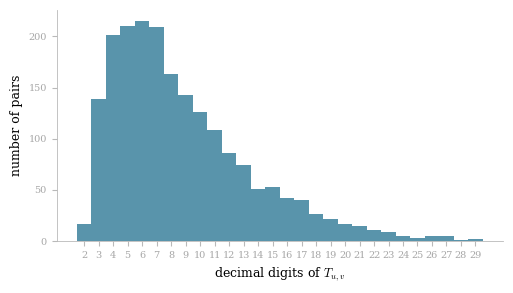

In [6]:
print(f"lcm(1, ..., m) of the graph has {len(str(system_period(G)))} digits")
for B, run in runs.items():
    for name in ("initial", "final"):
        T = math.lcm(*[bus.P_b for bus in run[name].buses.values()])
        print(f"{B:>4} buses, {name:>7}: system period T has {len(str(T))} digits")

values = pair_periods(runs[DETAILED]["final"])
print(f"\n{DETAILED} buses, final system: T_uv over {len(values)} random pairs, "
      f"median {statistics.median(len(str(value)) for value in values):.0f} digits, "
      f"largest {len(str(max(values)))} digits")
pair_period_histogram(runs[DETAILED]["final"], filename=f"{FIGURES}/pair_periods_N{DETAILED}.pdf");

## Convergence on the Search and on the Evaluation Sample

1000 buses
         0  search  81.2303  evaluation  81.4950  [80.3808, 82.6092]
     25000  search  79.2542  evaluation  80.8061  [79.7055, 81.9066]
     50000  search  77.6199  evaluation  80.5371  [79.4370, 81.6372]
     75000  search  76.8931  evaluation  80.2448  [79.1537, 81.3359]
    100000  search  76.3721  evaluation  80.1005  [79.0109, 81.1901]
    125000  search  76.1339  evaluation  80.0569  [78.9682, 81.1456]
    150000  search  75.6886  evaluation  80.0655  [78.9758, 81.1553]
    175000  search  75.4374  evaluation  79.9798  [78.8915, 81.0682]
    200000  search  75.0417  evaluation  79.8343  [78.7544, 80.9143]
    225000  search  74.7119  evaluation  79.7404  [78.6613, 80.8195]
    250000  search  74.6229  evaluation  79.7331  [78.6539, 80.8123]
    275000  search  74.3245  evaluation  79.7466  [78.6680, 80.8252]
    300000  search  74.2131  evaluation  79.7315  [78.6531, 80.8099]
    325000  search  74.1029  evaluation  79.6848  [78.6076, 80.7621]
    350000  search  74.

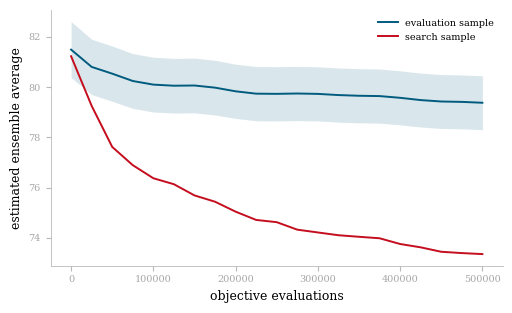

In [7]:
def plain_axes(ax):
    """Axis style of the thesis figures."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(figstyle.AXIS_GREY)
        ax.spines[side].set_linewidth(figstyle.LW_AXIS)
    ax.tick_params(labelsize=figstyle.FS_SCRIPT, color=figstyle.AXIS_GREY,
                   labelcolor=figstyle.LABEL_GREY)


def convergence_figure(trace, filename):
    """Estimate on the search sample against the estimate on the evaluation sample."""
    evaluations = [row["evaluations"] for row in trace]
    fig, ax = plt.subplots(figsize=(5.2, 3.2))
    ax.fill_between(evaluations, [row["eval_interval"][0] for row in trace],
                    [row["eval_interval"][1] for row in trace],
                    color=figstyle.TUBLUE, alpha=0.15, linewidth=0)
    ax.plot(evaluations, [row["eval_estimate"] for row in trace], color=figstyle.TUBLUE,
            linewidth=1.4, label="evaluation sample")
    ax.plot(evaluations, [row["search_estimate"] for row in trace], color=figstyle.TURED,
            linewidth=1.4, label="search sample")
    ax.set_xlabel("objective evaluations", fontsize=figstyle.FS_SMALL)
    ax.set_ylabel("estimated ensemble average", fontsize=figstyle.FS_SMALL)
    plain_axes(ax)
    ax.legend(fontsize=figstyle.FS_SCRIPT, frameon=False)
    fig.tight_layout()
    fig.savefig(filename)
    plt.show()


for B, run in runs.items():
    print(f"{B} buses")
    for row in run["trace"]:
        print(f"   {row['evaluations']:7d}  search {row['search_estimate']:8.4f}  "
              f"evaluation {row['eval_estimate']:8.4f}  "
              f"[{row['eval_interval'][0]:.4f}, {row['eval_interval'][1]:.4f}]")
    convergence_figure(run["trace"], f"{FIGURES}/convergence_N{B}.pdf")

## Example Bus Routes

The shortest, a median and the longest circuit of the final system, and the same three buses in the initial solution.

1000 buses: P_b [80, 98, 382] -> [76, 98, 378]


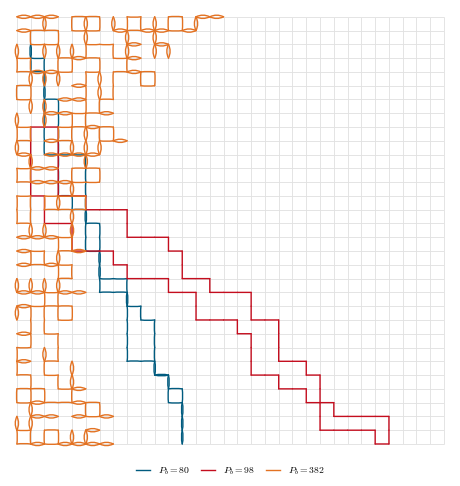

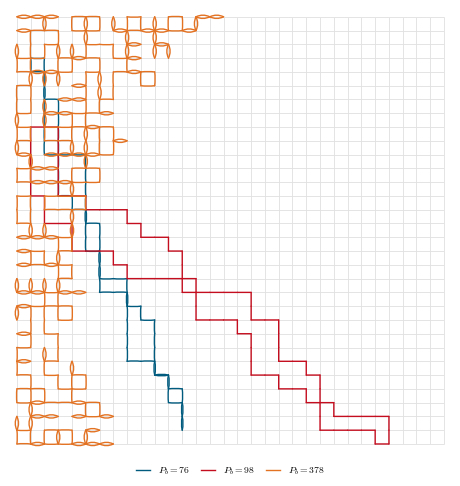

In [8]:
for B, run in runs.items():
    initial_examples, examples = examples_of(run)
    print(f"{B} buses: P_b {[bus.P_b for bus in initial_examples]} -> {[bus.P_b for bus in examples]}")
    route_figure(network, initial_examples, filename=f"{FIGURES}/example_routes_initial_N{B}.pdf")
    route_figure(network, examples, filename=f"{FIGURES}/example_routes_N{B}.pdf")

## Bus Lengths of the Whole Fleet

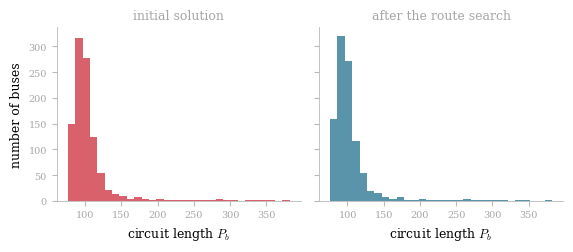

In [9]:
run = runs[DETAILED]
period_histogram({"initial solution": run["initial"], "after the route search": run["final"]},
                 filename=f"{FIGURES}/periods_N{DETAILED}.pdf");

## Load of the Underlying Undirected Network Edges

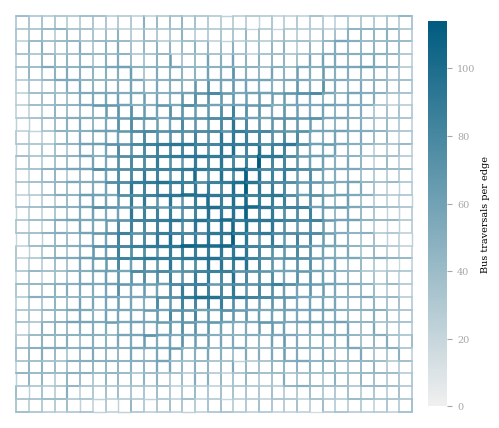

In [10]:
load_heatmap(network, run["final"], filename=f"{FIGURES}/load_N{DETAILED}.pdf");